<a href="https://colab.research.google.com/github/jfink09/SSI_Study/blob/main/RoB2_and_ROBINS_I_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

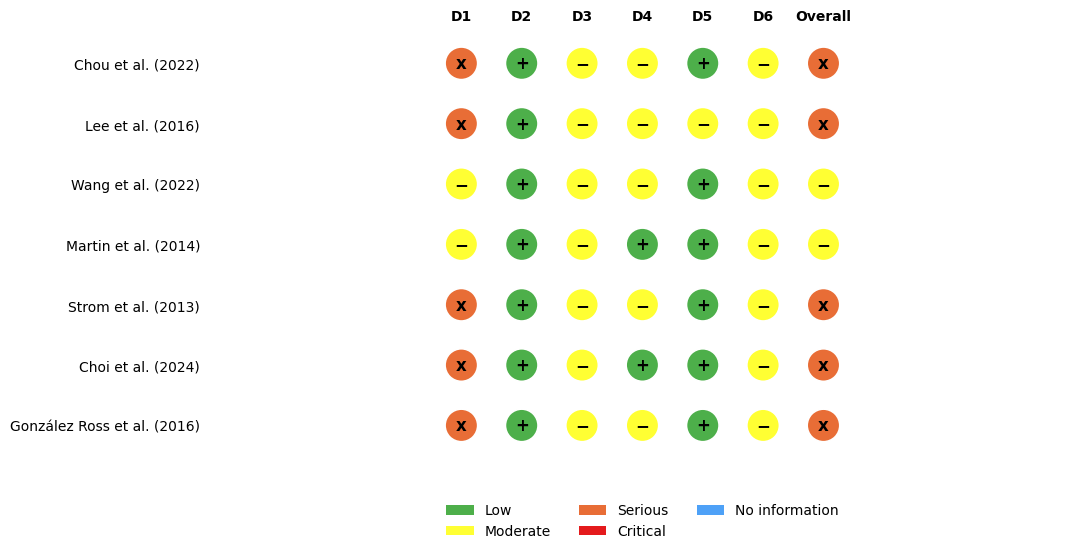

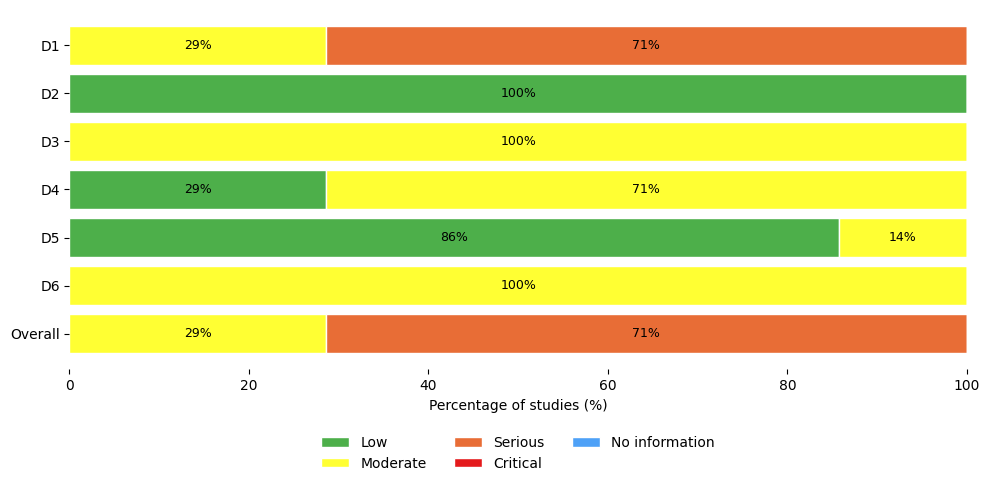

Both figures saved as PNG and PDF.


In [ ]:
# Install once if needed: pip install pandas openpyxl matplotlib numpy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Circle
from pathlib import Path


file_path = "ROBINS_SSI.xlsx"
df = pd.read_excel(file_path)

domains = ["D1", "D2", "D3", "D4", "D5", "D6", "Overall"]

ratings = [
    "Low", "Moderate", "Serious",
    "Critical", "No information"
]

colors = {
    "Low": "#4daf4a",
    "Moderate": "#ffff33",
    "Serious": "#E86D36",
    "Critical": "#e41a1c",
    "No information": "#4EA1F7"
}

# Validate data
df.columns = df.columns.astype(str).str.strip()
df = df.dropna(subset=["Study"])

missing = [c for c in domains if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

for col in domains:
    df[col] = df[col].astype(str).str.strip()
    invalid = set(df[col]) - set(ratings)
    if invalid:
        raise ValueError(f"Invalid ratings in {col}: {invalid}")


# ROBINS-I V2 traffic light plot (Figure 3)

n = len(df)
fig, ax = plt.subplots(
    figsize=(11, max(3.5, n * 0.55 + 1.8))
)

for i, row in df.reset_index(drop=True).iterrows():
    y = n - 1 - i
    for j, domain in enumerate(domains):
        rating = row[domain]

        circle = Circle(
            (j, y),
            radius=0.27,
            facecolor=colors[rating],
            edgecolor="white",
            linewidth=1.2
        )
        ax.add_patch(circle)

        symbol = {
            "Low": "+",
            "Moderate": "−",
            "Serious": "x",
            "Critical": "!",
            "No information": "?"
        }[rating]

        ax.text(
            j, y, symbol,
            ha="center", va="center",
            fontsize=12, fontweight="bold",
            color="black"
        )

ax.set_xlim(-0.6, len(domains) - 0.4)
ax.set_ylim(-0.7, n - 0.3)

ax.set_xticks(range(len(domains)))
ax.set_xticklabels(domains, fontweight="bold")

ax.set_yticks(range(n))
ax.set_yticklabels(
    df["Study"].iloc[::-1], fontsize=10
)

ax.xaxis.tick_top()
ax.tick_params(length=0)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_aspect("equal", adjustable="datalim")

legend = [
    Patch(facecolor=colors[r], label=r)
    for r in ratings
]
ax.legend(
    handles=legend,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=3,
    frameon=False
)

plt.tight_layout()
plt.savefig("ROBINS_V2_Traffic_Light.png",
            dpi=300, bbox_inches="tight")
plt.savefig("ROBINS_V2_Traffic_Light.pdf",
            bbox_inches="tight")
plt.show()


# ROBINS-I V2 summary plot (Figure 4)


summary = pd.DataFrame(index=domains)

for rating in ratings:
    summary[rating] = [
        (df[d] == rating).mean() * 100
        for d in domains
    ]

fig, ax = plt.subplots(figsize=(10, 5))

left = np.zeros(len(domains))

for rating in ratings:
    values = summary[rating].values

    ax.barh(
        domains, values,
        left=left,
        color=colors[rating],
        edgecolor="white",
        label=rating
    )

    for i, value in enumerate(values):
        if value >= 7:
            ax.text(
                left[i] + value / 2,
                i,
                f"{value:.0f}%",
                ha="center",
                va="center",
                fontsize=9
            )

    left += values

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Percentage of studies (%)")

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
    frameon=False
)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig("ROBINS_V2_Summary.png",
            dpi=300, bbox_inches="tight")
plt.savefig("ROBINS_V2_Summary.pdf",
            bbox_inches="tight")
plt.show()

print("Both figures saved as PNG and PDF.")

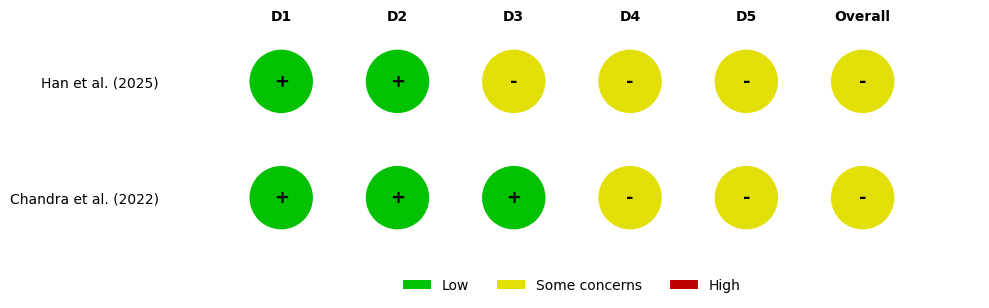

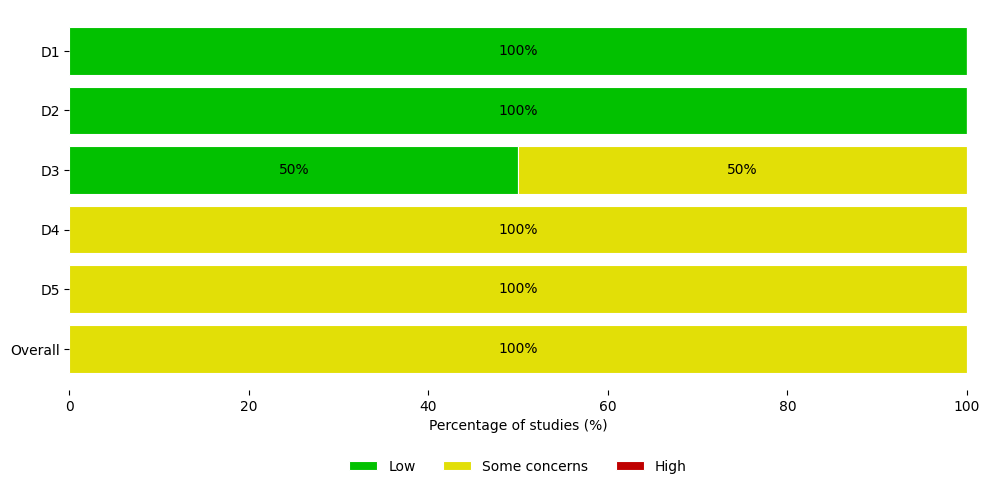

All RoB 2 figures successfully exported.


In [ ]:

# pip install pandas openpyxl matplotlib numpy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Patch


file_path = "ROB2_example.xlsx"

df = pd.read_excel(file_path)

domains = ["D1", "D2", "D3", "D4", "D5", "Overall"]

ratings = ["Low", "Some concerns", "High"]

colors = {
    "Low": "#02C100",
    "Some concerns": "#E2DF07",
    "High": "#BF0000"
}

symbols = {
    "Low": "+",
    "Some concerns": "-",
    "High": "x"
}

# Validate data

df.columns = df.columns.astype(str).str.strip()
df = df.dropna(subset=["Study"]).copy()

required = ["Study"] + domains
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

for col in domains:
    df[col] = df[col].astype(str).str.strip()
    invalid = set(df[col]) - set(ratings)
    if invalid:
        raise ValueError(
            f"Invalid ratings in {col}: {invalid}"
        )

# RoB 2 traffic light plot (Figure 1)

n = len(df)
fig, ax = plt.subplots(
    figsize=(10, max(3.2, n * 0.6 + 1.7))
)

for i, (_, row) in enumerate(df.iterrows()):
    y = n - 1 - i

    for j, domain in enumerate(domains):
        rating = row[domain]

        circle = Circle(
            (j, y),
            radius=0.28,
            facecolor=colors[rating],
            edgecolor="white",
            linewidth=1.2
        )
        ax.add_patch(circle)

        ax.text(
            j, y, symbols[rating],
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold",
            color="black"
        )

ax.set_xlim(-0.5, len(domains) - 0.5)
ax.set_ylim(-0.6, n - 0.4)

ax.set_xticks(range(len(domains)))
ax.set_xticklabels(domains, fontweight="bold")
ax.xaxis.tick_top()

ax.set_yticks(range(n))
ax.set_yticklabels(
    df["Study"].iloc[::-1],
    fontsize=10
)

ax.tick_params(axis="both", length=0)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_aspect("equal", adjustable="datalim")

legend = [
    Patch(facecolor=colors[r], label=r)
    for r in ratings
]

ax.legend(
    handles=legend,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=3,
    frameon=False
)

plt.tight_layout()

plt.savefig(
    "ROB2_Traffic_Light.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "ROB2_Traffic_Light.pdf",
    bbox_inches="tight"
)

plt.show()

# RoB 2 summary plot (Figure 2)

summary = pd.DataFrame(index=domains)

for rating in ratings:
    summary[rating] = [
        (df[d] == rating).mean() * 100
        for d in domains
    ]

fig, ax = plt.subplots(figsize=(10, 5))

left = np.zeros(len(domains))

for rating in ratings:
    values = summary[rating].values

    ax.barh(
        domains,
        values,
        left=left,
        color=colors[rating],
        edgecolor="white",
        linewidth=0.8,
        label=rating
    )

    for i, value in enumerate(values):
        if value >= 7:
            ax.text(
                left[i] + value / 2,
                i,
                f"{value:.0f}%",
                ha="center",
                va="center",
                fontsize=10,
                fontweight="medium"
            )

    left += values

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Percentage of studies (%)")

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
    frameon=False
)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()

plt.savefig(
    "ROB2_Summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    "ROB2_Summary.pdf",
    bbox_inches="tight"
)

plt.show()

print("All RoB 2 figures successfully exported.")